# Vecinos más cercanos y máquinas de soporte vectorial

Este capítulo presenta dos clasificadores que, a diferencia de los modelos lineales generalizados, no suponen una forma funcional para la frontera entre clases: el de los $k$ vecinos más cercanos, el más simple de todos, y las máquinas de soporte vectorial, uno de los más potentes antes de la llegada del aprendizaje profundo {cite}`james2021,hastie2009`.

## k vecinos más cercanos

El método de los $k$ vecinos más cercanos (KNN) clasifica una observación nueva según la clase mayoritaria de las $k$ observaciones de entrenamiento más cercanas; en regresión, promedia sus valores. Es no paramétrico, porque no supone nada sobre la forma de la relación, y "perezoso", porque no construye un modelo: guarda los datos y calcula las distancias en el momento de predecir. Con $k = 1$ la frontera sigue cada punto de entrenamiento (una teselación de Voronoi) y el modelo tiene varianza muy alta; al aumentar $k$ la frontera se suaviza y el sesgo crece.

La distancia más usada es la de Minkowski, $d = \left(\sum_j |x_j - z_j|^\lambda\right)^{1/\lambda}$, que con $\lambda = 2$ es la euclidiana, con $\lambda = 1$ la de Manhattan y con $\lambda \to \infty$ la de Chebyshev. Como depende de las magnitudes, las variables deben escalarse. KNN sufre mucho la maldición de la dimensionalidad, y para conjuntos grandes usa estructuras como los árboles k-d o ball tree para buscar vecinos sin calcular todas las distancias.

Se usa como ejemplo una clasificación de facies a partir de dos registros de pozo simulados, el rayo gamma y la porosidad neutrónica.

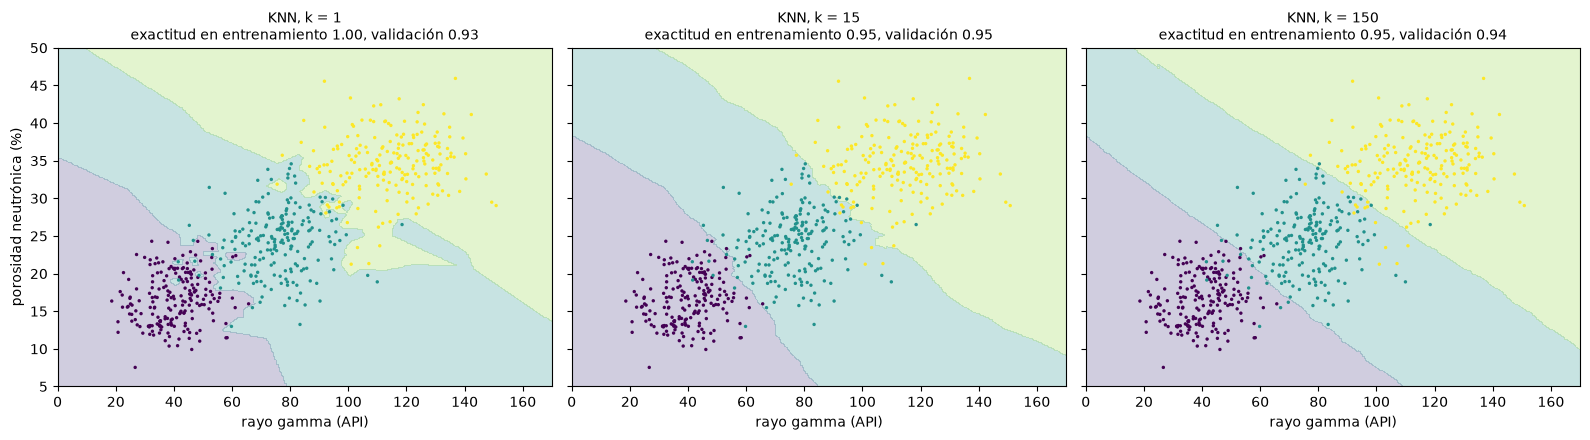

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, GridSearchCV, StratifiedKFold
plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(11)

def facies(n=600):
    """Tres facies: arenisca limpia, arenisca arcillosa y lutita, en el plano rayo gamma (API) - porosidad neutrónica (%)."""
    gr = np.concatenate([rng.normal(40, 10, n // 3), rng.normal(75, 12, n // 3), rng.normal(115, 15, n // 3)])
    nphi = np.concatenate([rng.normal(18, 3, n // 3), rng.normal(24, 4, n // 3), rng.normal(33, 4, n // 3)])
    nphi += 0.04 * (gr - 75) * rng.normal(1, 0.3, n)                      # curvatura de la relación
    y = np.repeat([0, 1, 2], n // 3)
    return np.column_stack([gr, nphi]), y

X, y = facies()
nombres = ['arenisca limpia', 'arenisca arcillosa', 'lutita']
g1, g2 = np.meshgrid(np.linspace(0, 170, 300), np.linspace(5, 50, 300))
malla = np.column_stack([g1.ravel(), g2.ravel()])

def frontera(ax, modelo, titulo):
    modelo.fit(X, y)
    ax.contourf(g1, g2, modelo.predict(malla).reshape(g1.shape), alpha=0.25, cmap='viridis', levels=[-0.5, 0.5, 1.5, 2.5])
    ax.scatter(*X.T, c=y, cmap='viridis', s=6, edgecolor='none')
    cv = cross_val_score(modelo, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0)).mean()
    ax.set_title(f'{titulo}\nexactitud en entrenamiento {modelo.score(X, y):.2f}, validación {cv:.2f}', fontsize=10)
    ax.set_xlabel('rayo gamma (API)')

fig, axs = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, k in zip(axs, [1, 15, 150]):
    frontera(ax, make_pipeline(StandardScaler(), KNeighborsClassifier(k)), f'KNN, k = {k}')
axs[0].set_ylabel('porosidad neutrónica (%)')
plt.tight_layout(); plt.show()

Con $k = 1$ la exactitud de entrenamiento es perfecta pero la de validación es menor; con $k = 150$ la frontera es demasiado rígida. Un valor intermedio equilibra el sesgo y la varianza; en la práctica se elige por validación cruzada.

## Máquinas de soporte vectorial

Las máquinas de soporte vectorial (SVM) {cite}`cortes1995` buscan el hiperplano que separa las clases con el mayor margen posible, es decir, la mayor distancia a los puntos más cercanos de cada clase. Esos puntos, los vectores de soporte, son los únicos que definen la frontera, lo que hace al método eficiente en memoria. Como en la práctica las clases se traslapan, se permite que algunos puntos violen el margen, con un costo controlado por el parámetro $C$: un $C$ pequeño tolera más violaciones y da un margen amplio (menos varianza); un $C$ grande penaliza mucho los errores y ajusta la frontera a los datos de entrenamiento (más varianza).

Para fronteras no lineales se usa el truco del kernel: en lugar de transformar explícitamente los datos a un espacio de mayor dimensión donde sí sean separables linealmente, se reemplaza el producto interno por una función kernel que equivale a hacerlo. Los más usados son el lineal, el polinómico y el de base radial (RBF), $K(x, z) = e^{-\gamma\|x - z\|^2}$. El parámetro $\gamma$ define hasta dónde llega la influencia de cada punto de entrenamiento: con $\gamma$ pequeño la influencia llega lejos y la frontera es suave; con $\gamma$ grande solo cuentan los puntos muy cercanos y la frontera se ciñe a los datos.

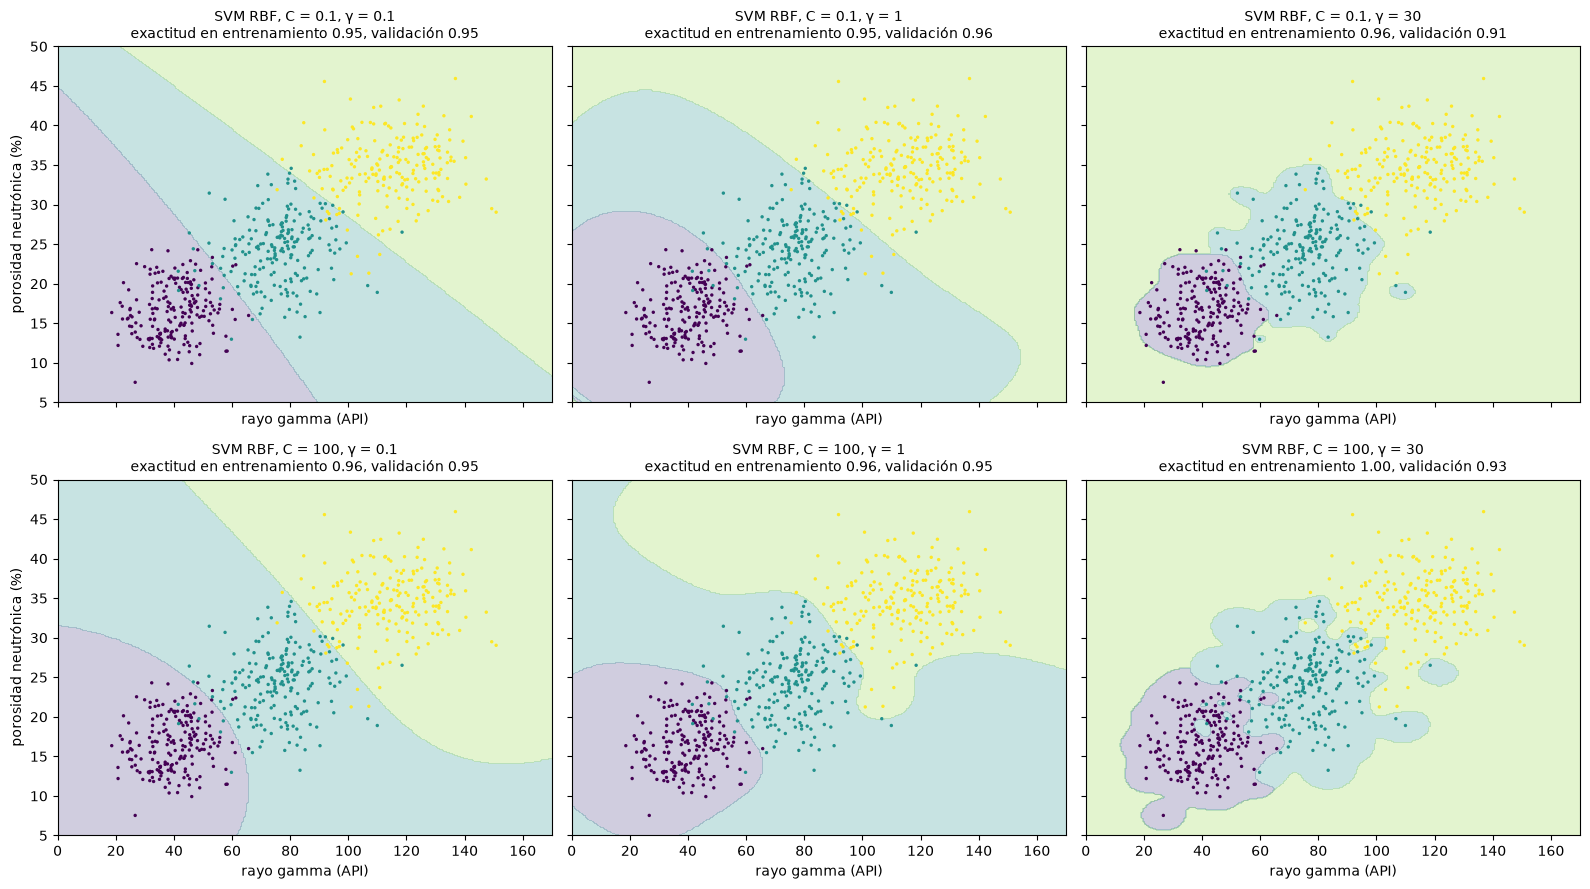

In [2]:
fig, axs = plt.subplots(2, 3, figsize=(16, 9), sharex=True, sharey=True)
for i, C in enumerate([0.1, 100]):
    for j, gamma in enumerate([0.1, 1, 30]):
        frontera(axs[i, j], make_pipeline(StandardScaler(), SVC(C=C, gamma=gamma)), f'SVM RBF, C = {C}, γ = {gamma}')
for a in axs[:, 0]: a.set_ylabel('porosidad neutrónica (%)')
plt.tight_layout(); plt.show()

La combinación de $C$ y $\gamma$ controla la complejidad: valores grandes de ambos producen fronteras recortadas alrededor de los puntos (sobreajuste). Se eligen juntos con búsqueda en malla y validación cruzada.

In [3]:
busq = GridSearchCV(make_pipeline(StandardScaler(), SVC()), {'svc__C': np.logspace(-2, 3, 6), 'svc__gamma': np.logspace(-2, 2, 5)},
                    cv=StratifiedKFold(5, shuffle=True, random_state=0)).fit(X, y)
print(f'Mejores hiperparámetros: C = {busq.best_params_["svc__C"]:.3g}, γ = {busq.best_params_["svc__gamma"]:.3g}; exactitud {busq.best_score_:.3f}')
knn = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()), {'kneighborsclassifier__n_neighbors': range(1, 80, 4)},
                   cv=StratifiedKFold(5, shuffle=True, random_state=0)).fit(X, y)
print(f'Mejor k para KNN: {knn.best_params_["kneighborsclassifier__n_neighbors"]}; exactitud {knn.best_score_:.3f}')

Mejores hiperparámetros: C = 1e+03, γ = 0.01; exactitud 0.958


Mejor k para KNN: 45; exactitud 0.955


Las SVM funcionan muy bien cuando hay un margen claro de separación, en espacios de alta dimensión e incluso cuando hay más variables que observaciones. Sus desventajas son el tiempo de entrenamiento con muchos datos (crece más que linealmente con $n$), el desempeño con clases muy traslapadas y que no entregan probabilidades directamente: `scikit-learn` las estima con una validación cruzada interna costosa (`probability=True`).

## Para profundizar

Las secciones 2.2.3 y 4.7 de {cite}`james2021` presentan KNN, y el capítulo 9, las máquinas de soporte vectorial. El capítulo 12 de {cite}`hastie2009` trata la teoría de las SVM. Los notebooks 17 (KNN) y 18 (SVM) del curso explican los hiperparámetros de `scikit-learn` con más ejemplos.